# 02 — Tests statistiques

Deux tests, chacun motivé par une question métier soulevée pendant l'EDA. Seuil de significativité : α = 0,05.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from shoppulse.geography import BrazilRegions
from shoppulse.warehouse import DataWarehouse

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
warehouse = DataWarehouse()

In [2]:
ORDERS_SQL = """
SELECT o.order_id,
    o.status,
    o.purchase_timestamp,
    o.delivered_customer_date,
    o.estimated_delivery_date,
    c.customer_unique_id,
    c.state,
    gc.lat,
    gc.lng,
    v.items_value,
    v.freight_value,
    r.score
FROM core.orders AS o
JOIN core.customers AS c ON c.customer_id = o.customer_id
LEFT JOIN core.geolocation AS gc ON gc.zip_code_prefix = c.zip_code_prefix
LEFT JOIN (
    SELECT order_id, SUM(price) AS items_value,
        SUM(freight_value) AS freight_value
    FROM core.order_items GROUP BY order_id
) AS v ON v.order_id = o.order_id
LEFT JOIN (
    SELECT order_id, MAX(score) AS score
    FROM core.order_reviews GROUP BY order_id
) AS r ON r.order_id = o.order_id
"""
orders = warehouse.query(ORDERS_SQL)
orders["region"] = orders["state"].map(BrazilRegions.of)
delivered = orders[
    (orders["status"] == "delivered")
    & orders["delivered_customer_date"].notna()
].copy()
delivered["delivery_days"] = (
    delivered["delivered_customer_date"] - delivered["purchase_timestamp"]
).dt.days
delivered["is_late"] = (
    delivered["delivered_customer_date"].dt.normalize()
    > delivered["estimated_delivery_date"].dt.normalize()
)
print(f"{len(orders):,} commandes, dont {len(delivered):,} livrées")

99,441 commandes, dont 96,470 livrées


## Test 1 — Les retards font-ils baisser les notes ?

**Question métier (service client)** : faut-il traiter les retards comme une cause majeure des avis négatifs ?

- H0 : les notes des commandes en retard et à l'heure suivent la même distribution.
- H1 : les notes des commandes en retard sont plus basses.

**Choix du test** : les notes sont ordinales (1 à 5) et loin d'une loi normale, donc pas de test t. On utilise le test non paramétrique de **Mann-Whitney U** (unilatéral). La taille d'effet est mesurée par la corrélation rang-bisériale.

In [3]:
reviewed = delivered.dropna(subset=["score"])
late_scores = reviewed.loc[reviewed["is_late"], "score"]
ontime_scores = reviewed.loc[~reviewed["is_late"], "score"]
u_stat, p_value = stats.mannwhitneyu(late_scores, ontime_scores,
                                     alternative="less")
rank_biserial = 1 - 2 * u_stat / (len(late_scores) * len(ontime_scores))
pd.Series({
    "commandes en retard": len(late_scores),
    "commandes à l'heure": len(ontime_scores),
    "note moyenne en retard": round(late_scores.mean(), 2),
    "note moyenne à l'heure": round(ontime_scores.mean(), 2),
    "U": u_stat,
    "p-value": p_value,
    "effet rang-bisérial": round(rank_biserial, 3),
})

commandes en retard       6.381000e+03
commandes à l'heure       8.944300e+04
note moyenne en retard    2.270000e+00
note moyenne à l'heure    4.290000e+00
U                         1.034023e+08
p-value                   0.000000e+00
effet rang-bisérial       6.380000e-01
dtype: float64

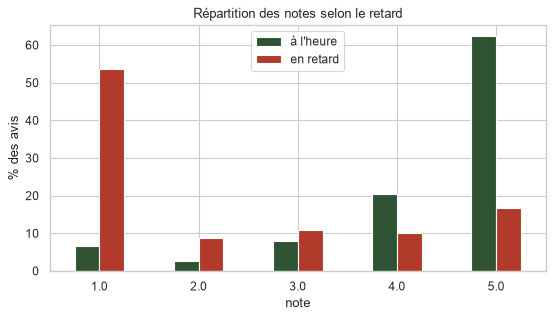

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
shares = pd.DataFrame({
    "à l'heure": ontime_scores.value_counts(normalize=True),
    "en retard": late_scores.value_counts(normalize=True),
}).sort_index() * 100
shares.plot.bar(ax=ax, color=["#2F5233", "#B23A2B"], rot=0)
ax.set(title="Répartition des notes selon le retard", xlabel="note",
       ylabel="% des avis")
plt.show()

**Conclusion** : la p-value est quasi nulle, on rejette H0. Les commandes en retard reçoivent des notes nettement plus basses (2,3 contre 4,3 en moyenne), avec un effet fort (rang-bisérial ≈ 0,64). **Décision métier** : prédire les retards (Lot 4) permet d'agir *avant* l'avis négatif, par exemple en prévenant le client ou en lui offrant un geste commercial.

## Test 2 — Le retard dépend-il de la région du client ?

**Question métier (logistique)** : les écarts de retard entre régions vus dans l'EDA sont-ils réels ou dus au hasard ?

- H0 : le fait d'être livré en retard est indépendant de la région.
- H1 : le retard dépend de la région.

**Choix du test** : deux variables catégorielles → test du **χ² d'indépendance**. Condition vérifiée : tous les effectifs attendus dépassent 5. Taille d'effet : **V de Cramér**.

In [5]:
table = pd.crosstab(delivered["region"], delivered["is_late"])
table.columns = ["à l'heure", "en retard"]
chi2, p_value, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
table["taux de retard (%)"] = (
    100 * table["en retard"] / table.sum(axis=1)
).round(1)
display(table.sort_values("taux de retard (%)", ascending=False))
pd.Series({
    "chi2": round(chi2, 1),
    "degrés de liberté": dof,
    "p-value": p_value,
    "effectif attendu minimal": round(expected.min(), 1),
    "V de Cramér": round(cramers_v, 3),
})

,à l'heure,en retard,taux de retard (%)
region,,,
Nordeste,7894,1150,12.7
Norte,1642,154,8.6
Centro-Oeste,5257,367,6.5
Sudeste,62145,4048,6.1
Sul,12998,815,5.9


chi2                         5.776000e+02
degrés de liberté            4.000000e+00
p-value                     1.104596e-123
effectif attendu minimal     1.216000e+02
V de Cramér                  7.700000e-02
dtype: float64

**Conclusion** : p-value quasi nulle, on rejette H0 : le retard dépend bien de la région. Le V de Cramér reste faible : la région joue, mais n'explique pas tout à elle seule (distance, vendeur, période comptent aussi). **Décisions** : (1) la région et la distance client-vendeur seront des variables du modèle de retard ; (2) le modèle risque d'être moins bon pour les régions peu représentées (Norte), d'où l'audit d'équité par région.